# SF Bay Area Bike Share: usage, availability and an OR business case
The current project compares no redistribution, a greedy rule and optimized bicycle transfers.
This EDA asks whether the new four-table dataset closes the inventory, capacity, unmet-demand and financial gaps identified in Citi Bike.
It analyzes all source rows. The large status history is queried from a local DuckDB database.
**Observed empty/full time is availability exposure, not a count of unfulfilled orders.**

In [1]:
from pathlib import Path
import sys, json, math
import numpy as np
import pandas as pd
import duckdb
import matplotlib
from IPython import get_ipython
IN_NOTEBOOK = get_ipython() is not None
if IN_NOTEBOOK:
    get_ipython().run_line_magic('matplotlib', 'inline')
else:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
ROOT = Path(__file__).resolve().parents[1] if '__file__' in globals() else Path.cwd()
if ROOT.name == 'sf_bikeshare':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'sf_bikeshare'))
from build_database import build, SOURCE_DEFAULT
OUT=ROOT/'output/sf_bikeshare'
FIG=OUT/'figures'; FIG.mkdir(parents=True,exist_ok=True)
con=duckdb.connect(str(build()),read_only=True)
con.execute("SET memory_limit='2GB'"); con.execute('SET threads=4')
pd.set_option('display.max_columns',18)
sns.set_theme(style='whitegrid',palette='colorblind')
BLUE,ORANGE,TEAL,RED='#2568ad','#dc942c','#008b81','#b74b4b'
plt.rcParams.update({'figure.dpi':105,'savefig.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
def say(s):
    if IN_NOTEBOOK: display(Markdown(s))
    else: print(s.encode(sys.stdout.encoding or 'utf-8',errors='replace').decode(sys.stdout.encoding or 'utf-8'),flush=True)
def q(sql): return con.execute(sql).df()
def export(df,name):
    df.to_csv(OUT/f'{name}.csv',index=False)
    return df
def show(df): display(df)
figure_notes=[]
def save(fig,name,question,answer):
    fig.tight_layout(); fig.savefig(FIG/f'{name}.png',bbox_inches='tight',facecolor='white')
    if IN_NOTEBOOK: plt.show()
    plt.close(fig)
    figure_notes.append({'figure':name+'.png','question':question,'interpretation':answer})
    say('**'+question+'** '+answer)
metrics={}

Using verified, unchanged local database cache.


## 1. What do the tables contain, and can their keys be trusted?
Station is a location dimension. Trip is one completed ride. Status is one station snapshot.
Weather is one location-day. A bicycle ID is not a customer ID; no individual rider identifier is supplied.
The status composite key is checked across the full file. The large raw table has an audited logical key;
small-table unique indexes enforce their keys without an enormous raw-status index.

,table_name,key_columns,rows,distinct_keys
0,station,station_id,70,70.0
1,trip,trip_id,669959,669959.0
2,bike,bike_id,700,700.0
3,weather,weather_zip_code + weather_date,3665,3665.0
4,status,station_id + observed_at,71984434,71984434.0
5,status_hourly,station_id + hour_start,1204554,1204554.0


,source_rows,parse_or_missing,unknown_stations,negative_counts,both_zero,static_capacity_mismatches,first_observation,last_observation,stations
0,71984434,0,0,0,240,3403916,2013-08-29 12:06:01,2015-08-31 23:59:02,70


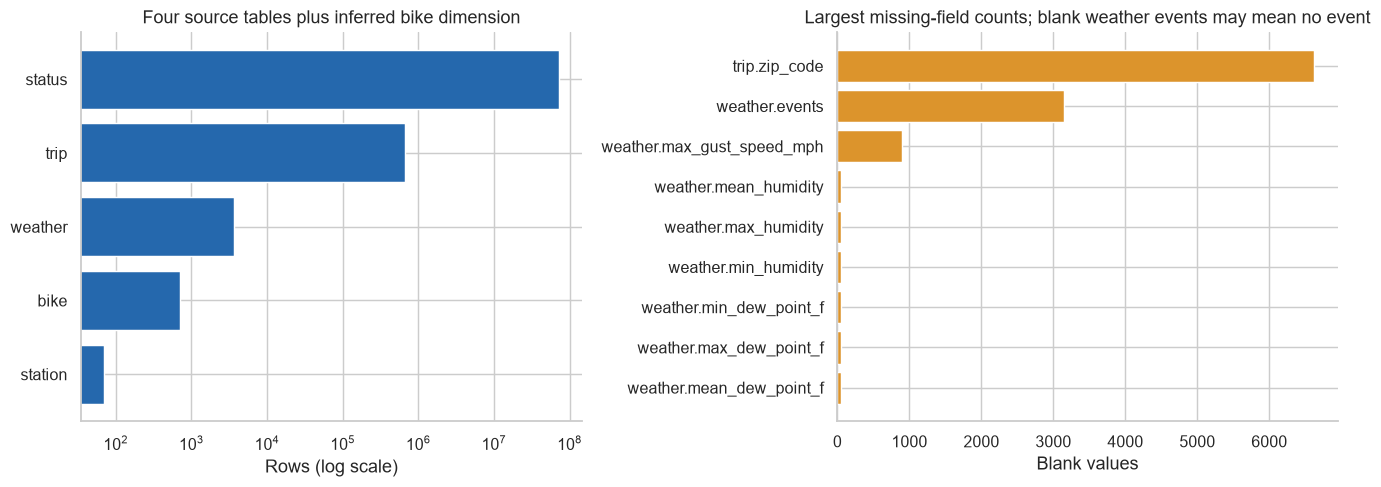

**Is the new dataset relationally usable?** 669,959 valid trips, 70 stations and 71,984,434 raw status snapshots. See the key and quality audits before joining.

In [2]:
keys=export(q('SELECT * FROM key_audit'),'key_audit'); show(keys)
station=q('SELECT * FROM station ORDER BY station_id').set_index('station_id')
trips=q('SELECT * FROM valid_trip')
weather=q('SELECT * FROM weather')
status_quality=export(q('SELECT * FROM status_quality'),'status_quality'); show(status_quality)
export(q('SELECT * FROM status_duplicate_keys'),'status_duplicate_keys')
gaps=export(q('SELECT * FROM interval_gap_audit'),'interval_gap_audit')
month_coverage=export(q('SELECT * FROM status_month_coverage'),'status_month_coverage')
start,end=trips.started_at.min(),trips.started_at.max()
dates=pd.date_range(start.normalize(),end.normalize(),freq='D')
metrics.update(raw_trip_rows=int(keys.loc[keys.table_name.eq('trip'),'rows'].iloc[0]),
    valid_trips=len(trips),stations=len(station),bicycles=int(keys.loc[keys.table_name.eq('bike'),'rows'].iloc[0]),
    weather_rows=len(weather),status_rows=int(status_quality.source_rows.iloc[0]),
    start=str(start),end=str(end),days=len(dates),subscriber_share_pct=100*trips.subscription_type.eq('Subscriber').mean(),
    median_duration_minutes=float(trips.duration_minutes.median()),long_trips=int(trips.long_trip.sum()))
source_files=json.loads((OUT/'source_manifest.json').read_text())['files']
source_dir=SOURCE_DEFAULT
quality=[]
for name in ['station','trip','weather']:
    raw=pd.read_csv(source_dir/(name+'.csv'),dtype='string')
    for col in raw:
        quality.append({'table':name,'column':col,'rows':len(raw),'missing':int(raw[col].isna().sum()),
                        'distinct_nonmissing':int(raw[col].nunique())})
for col in ['station_id','bikes_available','docks_available','observed_at']:
    missing=q(f'SELECT count(*) FILTER(WHERE {col} IS NULL) n FROM status').n.iloc[0]
    quality.append({'table':'status','column':col,'rows':metrics['status_rows'],'missing':int(missing),'distinct_nonmissing':np.nan})
quality=export(pd.DataFrame(quality),'column_quality')
trip_audit=export(q("""SELECT count(*) records,
 count(*) FILTER(WHERE started_at IS NULL OR ended_at IS NULL) missing_or_bad_times,
 count(*) FILTER(WHERE duration_seconds<=0) nonpositive_reported_duration,
 count(*) FILTER(WHERE ended_at<=started_at) nonpositive_clock_duration,
 count(*) FILTER(WHERE abs(date_diff('second',started_at,ended_at)-duration_seconds)>60) duration_clock_mismatch_over_60s,
 count(*) FILTER(WHERE duration_seconds>86400) reported_duration_over_24h,
 count(*) FILTER(WHERE rider_zip_code IS NULL) missing_rider_zip,
 count(*) FILTER(WHERE bike_id IS NULL) missing_bike_id FROM trip"""),'trip_quality')
name_audit=export(q("""SELECT t.start_station_id station_id,s.station_name,count(DISTINCT t.start_station_name) observed_start_names,
 string_agg(DISTINCT t.start_station_name,'; ') observed_names FROM trip t JOIN station s ON t.start_station_id=s.station_id
 GROUP BY 1,2 HAVING count(DISTINCT t.start_station_name)>1 OR bool_or(t.start_station_name<>s.station_name)"""),'station_name_changes')
metrics['duration_clock_mismatches']=int(trip_audit.duration_clock_mismatch_over_60s.iloc[0])
export(q("""SELECT bike_id,count(*) trips,min(started_at) first_trip,max(ended_at) last_trip,
 sum(duration_seconds)/3600.0 reported_ride_hours FROM valid_trip GROUP BY 1 ORDER BY trips DESC"""),'bike_usage')
export(q("""WITH ordered AS (SELECT *,lag(ended_at) OVER(PARTITION BY bike_id ORDER BY started_at,trip_id) previous_end,
 lag(end_station_id) OVER(PARTITION BY bike_id ORDER BY started_at,trip_id) previous_destination FROM valid_trip)
 SELECT count(*) consecutive_trip_pairs,
 count(*) FILTER(WHERE previous_end>started_at+INTERVAL 1 MINUTE) overlap_over_1min,
 count(*) FILTER(WHERE previous_destination<>start_station_id) station_discontinuities
 FROM ordered WHERE previous_end IS NOT NULL"""),'bike_sequence_audit')
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
sizes=keys.set_index('table_name').reindex(['station','bike','weather','trip','status']).rows
axes[0].barh(sizes.index,sizes,color=BLUE); axes[0].set_xscale('log'); axes[0].set(xlabel='Rows (log scale)',title='Four source tables plus inferred bike dimension')
missing=quality[quality.missing.gt(0)].sort_values('missing').tail(9)
axes[1].barh(missing.table+'.'+missing.column,missing.missing,color=ORANGE)
axes[1].set(xlabel='Blank values',title='Largest missing-field counts; blank weather events may mean no event')
save(fig,'01_source_quality','Is the new dataset relationally usable?',
     f'{len(trips):,} valid trips, {len(station)} stations and {metrics["status_rows"]:,} raw status snapshots. See the key and quality audits before joining.')

## 2. What is connected to what?
Join station IDs to both trip endpoints and to status. Bike IDs define an observed-bike dimension.
Weather needs the explicit city-weather proxy table and date, not the rider postal code.
Never join two facts on station alone: aggregate to a common station-hour or use timestamp-aware joins.

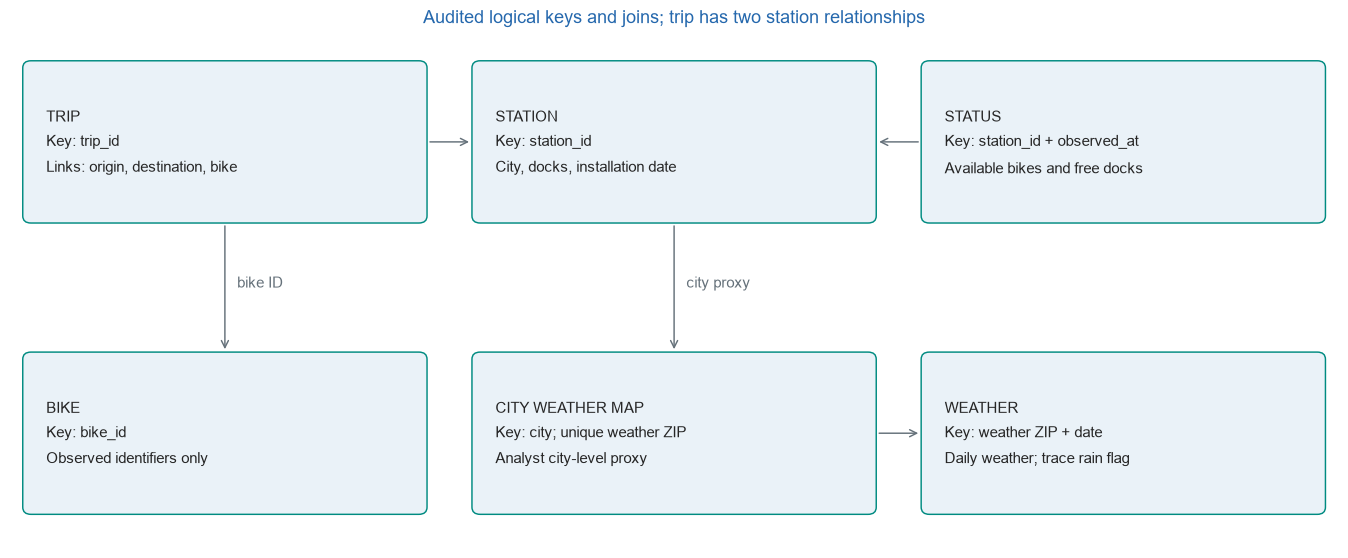

**Which keys and relationships should the database use?** Trip IDs, station IDs and weather location-dates identify different grains. The city-weather link is explicit and approximate; rider ZIP is never a weather key.

In [3]:
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(13,5.5)); ax.set(xlim=(0,13),ylim=(0,6)); ax.axis('off')
boxes={
 'trip':(.2,3.7,'TRIP\nKey: trip_id\nLinks: origin, destination, bike'),
 'station':(4.6,3.7,'STATION\nKey: station_id\nCity, docks, installation date'),
 'status':(9,3.7,'STATUS\nKey: station_id + observed_at\nAvailable bikes and free docks'),
 'bike':(.2,.45,'BIKE\nKey: bike_id\nObserved identifiers only'),
 'map':(4.6,.45,'CITY WEATHER MAP\nKey: city; unique weather ZIP\nAnalyst city-level proxy'),
 'weather':(9,.45,'WEATHER\nKey: weather ZIP + date\nDaily weather; trace rain flag')}
bw,bh=3.8,1.65
for name,(x,y,label) in boxes.items():
    ax.add_patch(FancyBboxPatch((x,y),bw,bh,boxstyle='round,pad=.08',fc='#eaf2f8',ec=TEAL))
    ax.text(x+.15,y+bh/2,label,ha='left',va='center',fontsize=10.5,linespacing=1.8)
for a,b in [('trip','station'),('map','weather')]:
    x1,y1=boxes[a][:2]; x2,y2=boxes[b][:2]
    ax.annotate('',xy=(x2-.08,y2+bh/2),xytext=(x1+bw+.08,y1+bh/2),arrowprops={'arrowstyle':'->','color':'#65717a'})
ax.annotate('',xy=(8.48,4.525),xytext=(8.92,4.525),arrowprops={'arrowstyle':'->','color':'#65717a'})
for a,b,label in [('trip','bike','bike ID'),('station','map','city proxy')]:
    x1,y1=boxes[a][:2]; x2,y2=boxes[b][:2]
    ax.annotate('',xy=(x2+bw/2,y2+bh+.08),xytext=(x1+bw/2,y1-.08),arrowprops={'arrowstyle':'->','color':'#65717a'})
    ax.text(x1+bw/2+.12,2.9,label,fontsize=10,color='#65717a')
ax.text(6.5,5.85,'Audited logical keys and joins; trip has two station relationships',ha='center',fontsize=12,color=BLUE)
save(fig,'02_database_relationships','Which keys and relationships should the database use?',
     'Trip IDs, station IDs and weather location-dates identify different grains. The city-weather link is explicit and approximate; rider ZIP is never a weather key.')

## 3. How does usage vary over two years and across cities?
Counts are completed trips. First/last dates are boundary days, not necessarily full observation days.
Growth and seasonality are intertwined with station additions; daily counts are not a controlled causal comparison.

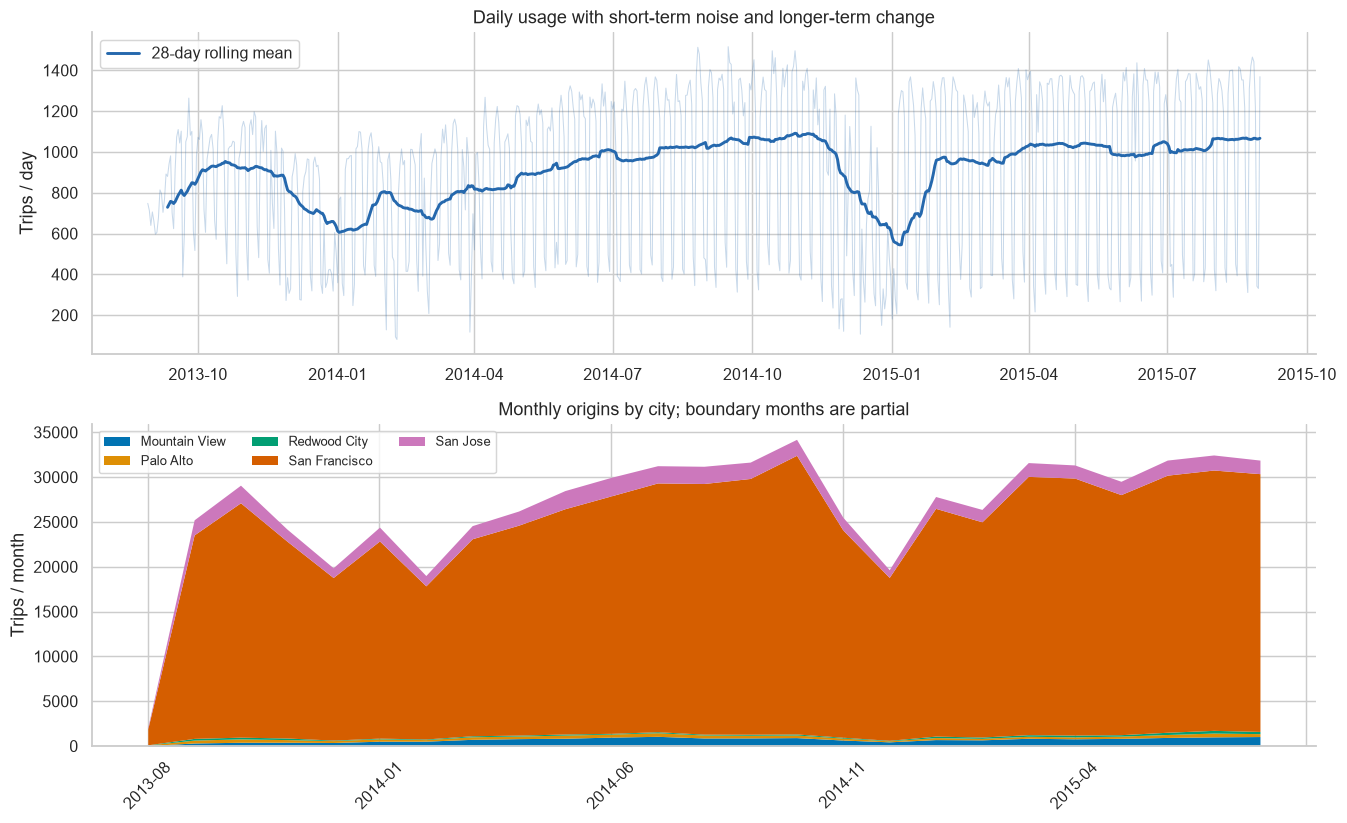

**Is demand stable over time and evenly spread across cities?** Compare city shares and within-period patterns rather than treating the two-year system total as a stationary demand rate.

In [4]:
daily=trips.groupby(trips.started_at.dt.normalize()).size().reindex(dates,fill_value=0).rename('departures').to_frame()
daily.index.name='date'; daily['day_type']=np.where(daily.index.day_of_week<5,'Weekday','Weekend')
export(daily.reset_index(),'daily_trips')
city_counts=export(trips.groupby('start_city').size().rename('trips').reset_index(),'city_trip_counts')
monthly=export(trips.groupby([trips.started_at.dt.to_period('M').astype(str),'start_city']).size().rename('trips').reset_index().rename(columns={'started_at':'month'}),'monthly_city_trips')
fig,axes=plt.subplots(2,1,figsize=(13,8))
axes[0].plot(daily.index,daily.departures,color=BLUE,alpha=.25,lw=.7)
axes[0].plot(daily.index,daily.departures.rolling(28,min_periods=14).mean(),color=BLUE,lw=2,label='28-day rolling mean')
axes[0].legend(); axes[0].set(ylabel='Trips / day',title='Daily usage with short-term noise and longer-term change')
pivot=monthly.pivot(index='month',columns='start_city',values='trips').fillna(0)
pivot.plot.area(ax=axes[1],linewidth=0); axes[1].set(ylabel='Trips / month',xlabel='',title='Monthly origins by city; boundary months are partial')
axes[1].legend(ncol=3,fontsize=9); axes[1].tick_params(axis='x',rotation=45)
save(fig,'03_usage_over_time','Is demand stable over time and evenly spread across cities?',
     'Compare city shares and within-period patterns rather than treating the two-year system total as a stationary demand rate.')

## 4. Are weekday and weekend peaks different?
Normalize by the number of calendar days of each type. Show weekday-hour averages and day-of-week heatmaps.

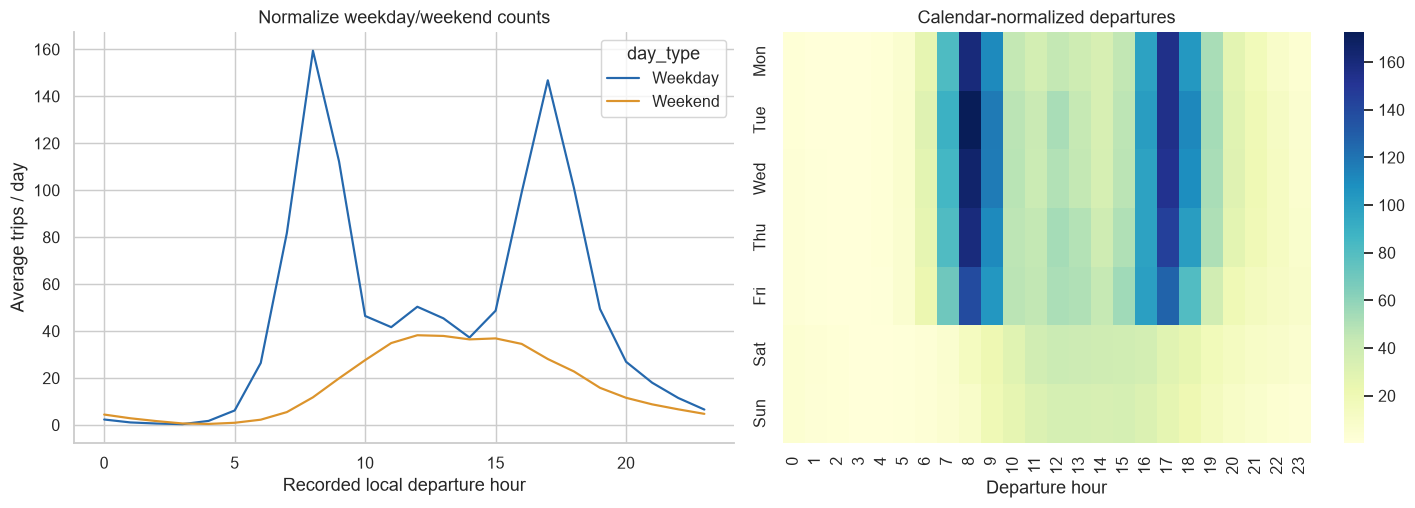

**When should redistribution be scheduled?** The busiest weekday hours are 08:00, 17:00, 09:00. A weekday peak is consistent with commuting, not proof of purpose.

In [5]:
trips['date']=trips.started_at.dt.normalize(); trips['hour']=trips.started_at.dt.hour
trips['day_type']=np.where(trips.started_at.dt.day_of_week<5,'Weekday','Weekend')
day_counts=pd.Series(np.where(dates.day_of_week<5,'Weekday','Weekend')).value_counts()
hour=trips.groupby(['day_type','hour']).size().rename('trips').reset_index()
hour['trips_per_calendar_day']=hour.trips/hour.day_type.map(day_counts)
export(hour,'hourly_usage_profile')
weekday_peak=hour[hour.day_type.eq('Weekday')].nlargest(3,'trips_per_calendar_day').hour.tolist()
metrics['top_weekday_hours']=[int(h) for h in weekday_peak]
heat=pd.crosstab(trips.started_at.dt.day_of_week,trips.hour).reindex(index=range(7),columns=range(24),fill_value=0)
heat=heat.div(pd.Series(dates.day_of_week).value_counts().reindex(range(7)),axis=0)
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.lineplot(data=hour,x='hour',y='trips_per_calendar_day',hue='day_type',ax=axes[0],palette=[BLUE,ORANGE])
axes[0].set(xlabel='Recorded local departure hour',ylabel='Average trips / day',title='Normalize weekday/weekend counts')
sns.heatmap(heat,ax=axes[1],cmap='YlGnBu',yticklabels=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
axes[1].set(xlabel='Departure hour',ylabel='',title='Calendar-normalized departures')
save(fig,'04_weekly_hourly_usage','When should redistribution be scheduled?',
     'The busiest weekday hours are '+', '.join(f'{h:02}:00' for h in weekday_peak)+'. A weekday peak is consistent with commuting, not proof of purpose.')

## 5. Who uses the system and how long are trips?
Reported duration is in seconds; timestamps are only minute-resolution. Rounding can create small discrepancies.
Long trips remain in the primary analysis and are checked in sensitivity; rider ZIP is not an individual identifier.

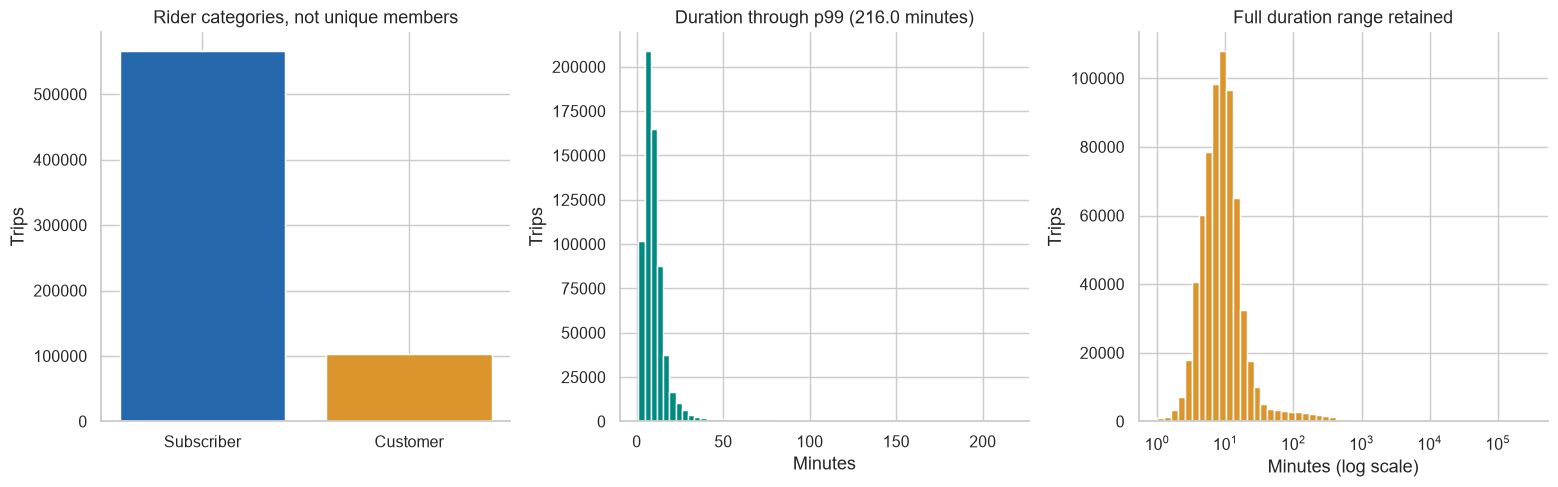

**Do usage categories establish revenue or maintenance demand?** Subscribers account for 84.6% of rides; the median is 8.62 minutes. 296 rides exceed 24 hours. No billing or work-order records are supplied.

In [6]:
duration=export(trips.groupby('subscription_type').duration_minutes.agg(trips='size',median='median',mean='mean',p95=lambda s:s.quantile(.95),p99=lambda s:s.quantile(.99)).reset_index(),'duration_by_subscription')
fig,axes=plt.subplots(1,3,figsize=(15,4.8))
mix=trips.subscription_type.value_counts(); axes[0].bar(mix.index,mix,color=[BLUE,ORANGE]); axes[0].set(ylabel='Trips',title='Rider categories, not unique members')
upper=trips.duration_minutes.quantile(.99)
axes[1].hist(trips.loc[trips.duration_minutes.le(upper),'duration_minutes'],bins=60,color=TEAL)
axes[1].set(xlabel='Minutes',ylabel='Trips',title=f'Duration through p99 ({upper:.1f} minutes)')
axes[2].hist(trips.duration_minutes,bins=np.geomspace(trips.duration_minutes.min(),trips.duration_minutes.max(),55),color=ORANGE)
axes[2].set_xscale('log'); axes[2].set(xlabel='Minutes (log scale)',ylabel='Trips',title='Full duration range retained')
save(fig,'05_rider_mix_and_duration','Do usage categories establish revenue or maintenance demand?',
     f'Subscribers account for {metrics["subscriber_share_pct"]:.1f}% of rides; the median is {metrics["median_duration_minutes"]:.2f} minutes. {metrics["long_trips"]:,} rides exceed 24 hours. No billing or work-order records are supplied.')

## 6. Which stations experience directional pressure?
Departures and arrivals use their own event timestamps. Average AM/PM windows are 07:00-09:59 and 16:00-18:59 on weekdays.
This is a two-year descriptive average, not a recommended initial inventory.

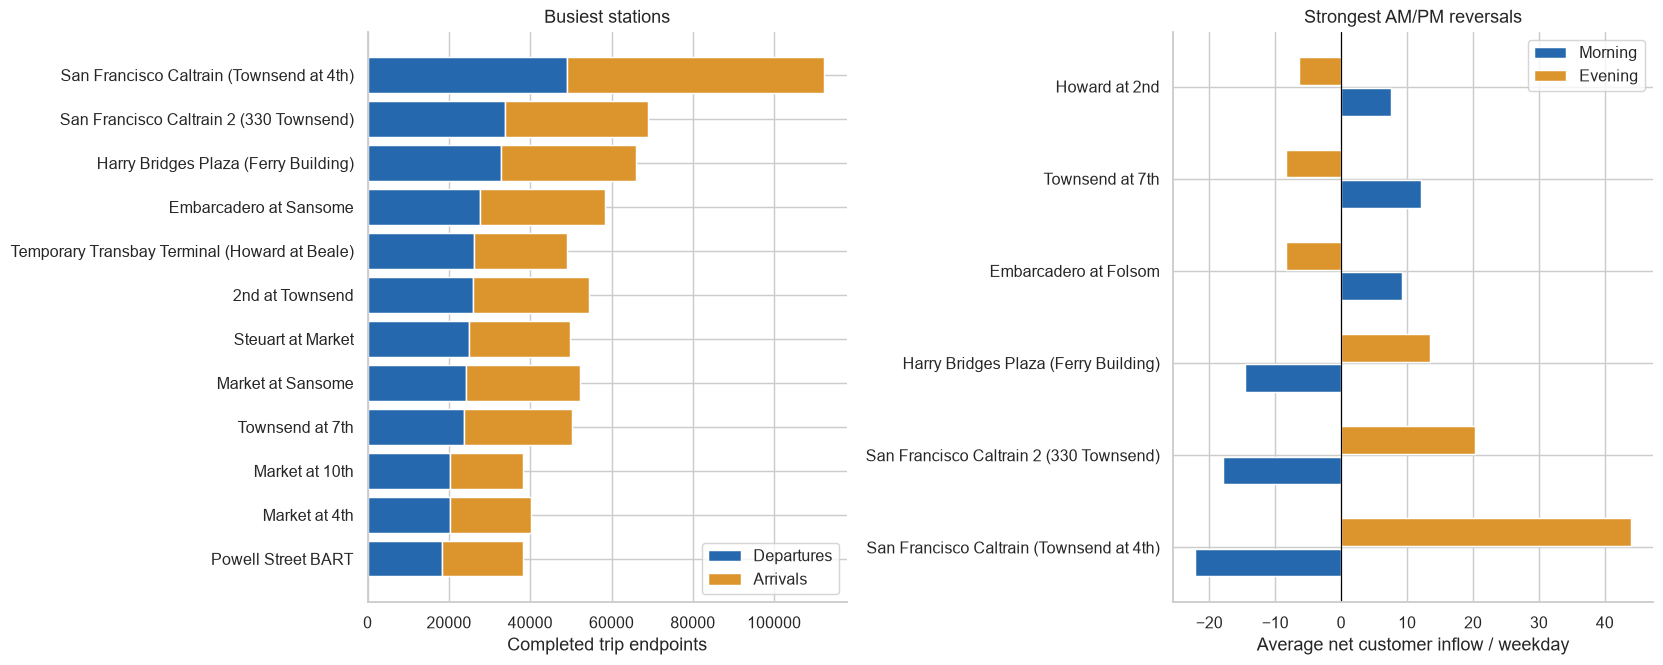

**Where do customer flows reverse direction?** 62 of 70 stations reverse average AM/PM sign. Monthly or full-period net balance alone does not represent hourly operating needs.

In [7]:
station_flows=export(q("""SELECT s.station_id,s.station_name,s.city,s.dock_count,
 sum(p.departures) departures,sum(p.arrivals) arrivals,sum(p.arrivals-p.departures) net_inflow
 FROM station s JOIN station_hour_panel p USING(station_id) GROUP BY 1,2,3,4"""),'station_flows').set_index('station_id')
windows=export(q("""SELECT station_id,
 avg(CASE WHEN hour BETWEEN 7 AND 9 THEN arrivals-departures END)*3 morning_net_per_weekday,
 avg(CASE WHEN hour BETWEEN 16 AND 18 THEN arrivals-departures END)*3 evening_net_per_weekday
 FROM station_hour_panel WHERE day_type='Weekday' GROUP BY 1"""),'weekday_peak_flows').set_index('station_id')
windows['reversal']=windows.morning_net_per_weekday*windows.evening_net_per_weekday<0
windows['magnitude']=np.minimum(windows.morning_net_per_weekday.abs(),windows.evening_net_per_weekday.abs()).where(windows.reversal,0)
export(windows.reset_index(),'morning_evening_reversal')
metrics['reversal_stations']=int(windows.reversal.sum())
top=station_flows.assign(activity=lambda x:x.departures+x.arrivals).nlargest(12,'activity')
selected=windows.nlargest(6,'magnitude').index
fig,axes=plt.subplots(1,2,figsize=(16,6.5))
top=top.sort_values('departures'); axes[0].barh(top.station_name,top.departures,color=BLUE,label='Departures'); axes[0].barh(top.station_name,top.arrivals,left=top.departures,color=ORANGE,label='Arrivals')
axes[0].legend(); axes[0].set(xlabel='Completed trip endpoints',title='Busiest stations')
for i,(c,color,label) in enumerate([('morning_net_per_weekday',BLUE,'Morning'),('evening_net_per_weekday',ORANGE,'Evening')]):
    axes[1].barh(np.arange(len(selected))+(i-.5)*.33,windows.loc[selected,c],height=.3,color=color,label=label)
axes[1].set_yticks(range(len(selected)),station.loc[selected,'station_name']); axes[1].axvline(0,color='black',lw=.8)
axes[1].legend(); axes[1].set(xlabel='Average net customer inflow / weekday',title='Strongest AM/PM reversals')
save(fig,'06_station_activity_and_reversal','Where do customer flows reverse direction?',
     f'{metrics["reversal_stations"]} of {len(station)} stations reverse average AM/PM sign. Monthly or full-period net balance alone does not represent hourly operating needs.')

## 7. Which routes and cities form natural modeling boundaries?
Cross-city pairs are observed, but relocation costs cannot be inferred from customer popularity or straight-line separation.

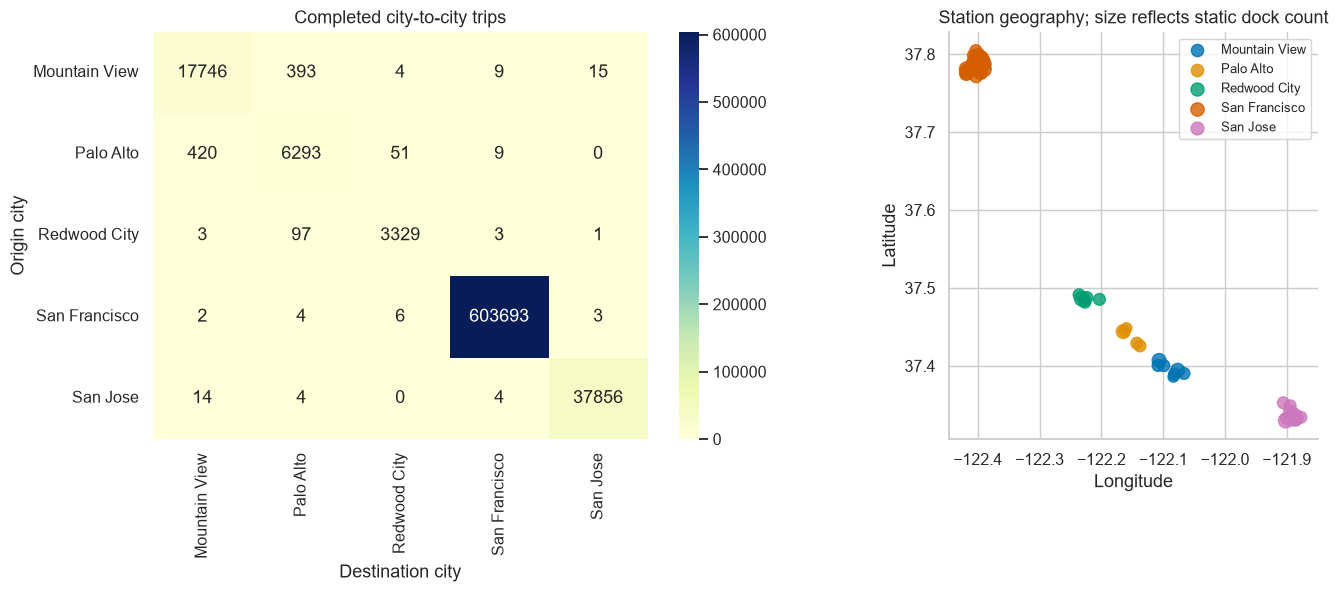

**Should all five cities be one redistribution problem?** Geography and observed corridors support starting with one city or a small station subset. A road-time matrix and depot/truck constraints remain necessary for routing.

In [8]:
od=export(trips.groupby(['start_station_id','end_station_id']).size().rename('trips').reset_index().sort_values('trips',ascending=False),'observed_od_counts')
city_od=pd.crosstab(trips.start_city,trips.end_city)
fig,axes=plt.subplots(1,2,figsize=(14,5.8))
sns.heatmap(city_od,annot=True,fmt='d',cmap='YlGnBu',ax=axes[0]); axes[0].set(title='Completed city-to-city trips',xlabel='Destination city',ylabel='Origin city')
for city,p in station.groupby('city'):
    axes[1].scatter(p.longitude,p.latitude,s=20+3*p.dock_count,label=city,alpha=.8)
axes[1].legend(fontsize=9); axes[1].set(xlabel='Longitude',ylabel='Latitude',title='Station geography; size reflects static dock count')
axes[1].set_aspect(1/np.cos(np.radians(37.5)))
save(fig,'07_network_and_routes','Should all five cities be one redistribution problem?',
     'Geography and observed corridors support starting with one city or a small station subset. A road-time matrix and depot/truck constraints remain necessary for routing.')

## 8. Is the status history continuous and are capacities stable?
Use the previous observed state only until the next observation when the gap is at most 90 seconds.
Longer gaps and zero-total-availability states are unknown exposure, not operational success or failure.
Time intervals crossing an hour are split exactly. Static dock count is checked against bikes + free docks.

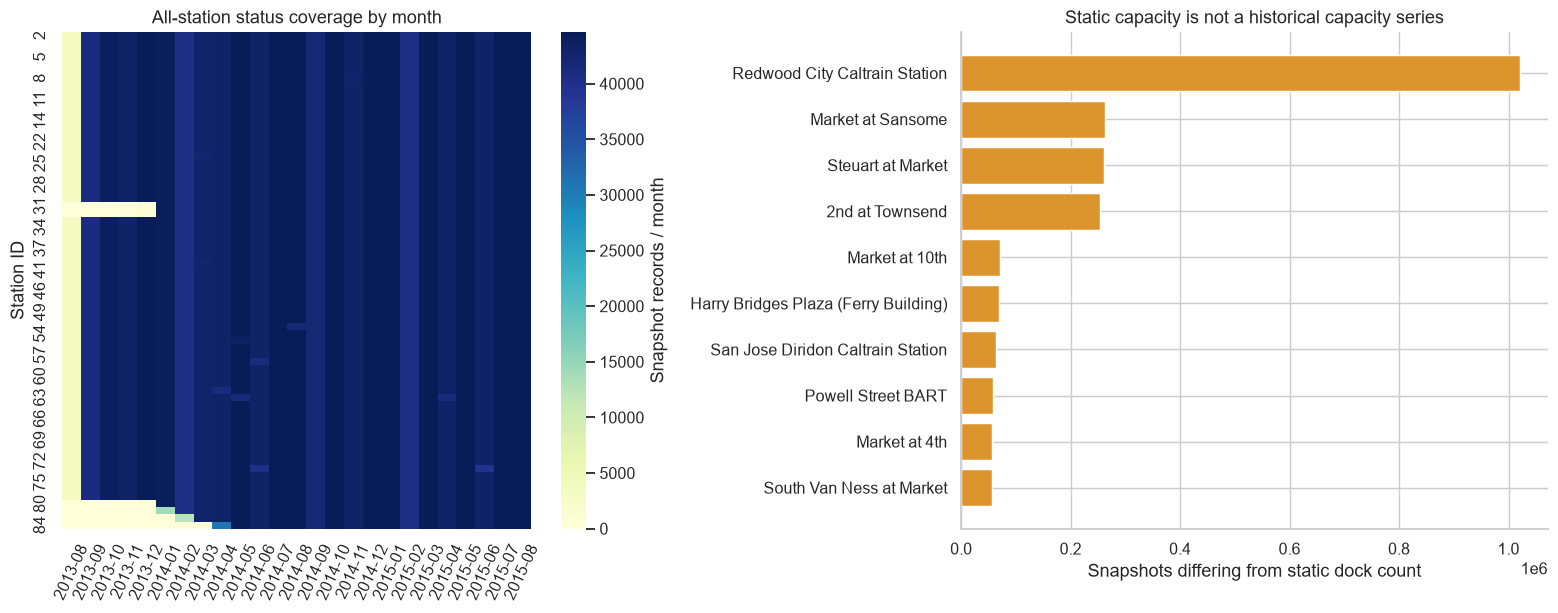

**Can we use every minute and the listed capacity without checking?** Valid short-gap exposure covers 98.9% of the installation-based calendar reference. 3,403,916 snapshots differ from static capacity; 240 have no available bikes or docks. Inspect these before modeling.

In [9]:
coverage=export(q("""SELECT station_id,city,sum(observed_seconds)/3600 observed_hours,
 sum(expected_hours) reference_hours,sum(observed_seconds)/(3600*sum(expected_hours)) coverage,
 count(*) reference_days,count(*) FILTER(WHERE observed_seconds>=.9*86400) days_at_least_90pct
 FROM station_daily GROUP BY 1,2"""),'station_coverage')
cap=export(q("""SELECT st.station_id,s.station_name,s.dock_count,
 min(bikes_available+docks_available) min_available_total,max(bikes_available+docks_available) max_available_total,
 count(*) records,count(*) FILTER(WHERE bikes_available+docks_available<>s.dock_count) mismatch_records
 FROM status st JOIN station s USING(station_id)
 WHERE bikes_available>=0 AND docks_available>=0 GROUP BY 1,2,3"""),'capacity_audit')
metrics['status_static_capacity_mismatch_rows']=int(status_quality.static_capacity_mismatches.iloc[0])
metrics['status_both_zero_rows']=int(status_quality.both_zero.iloc[0])
metrics['status_coverage_pct']=float(100*coverage.observed_hours.sum()/coverage.reference_hours.sum())
cm=month_coverage.pivot(index='station_id',columns='month',values='observations').fillna(0)
cm.columns=pd.to_datetime(cm.columns).strftime('%Y-%m')
fig,axes=plt.subplots(1,2,figsize=(15,6))
sns.heatmap(cm,cmap='YlGnBu',ax=axes[0],cbar_kws={'label':'Snapshot records / month'})
axes[0].set(xlabel='',ylabel='Station ID',title='All-station status coverage by month'); axes[0].tick_params(axis='x',rotation=65)
p=cap.nlargest(10,'mismatch_records').sort_values('mismatch_records')
axes[1].barh(p.station_name,p.mismatch_records,color=ORANGE); axes[1].set(xlabel='Snapshots differing from static dock count',title='Static capacity is not a historical capacity series')
save(fig,'08_status_coverage_and_capacity','Can we use every minute and the listed capacity without checking?',
     f'Valid short-gap exposure covers {metrics["status_coverage_pct"]:.1f}% of the installation-based calendar reference. {metrics["status_static_capacity_mismatch_rows"]:,} snapshots differ from static capacity; {metrics["status_both_zero_rows"]:,} have no available bikes or docks. Inspect these before modeling.')

## 9. How much observed time is empty or full?
Rates use valid observed seconds as denominator, not trip count and not the full calendar where status is missing.
Empty means zero available bikes with a positive total. Full means zero free docks with a positive total.
Both-zero records are excluded as ambiguous outages/unavailability. Reference calendar hours do not establish station operation.

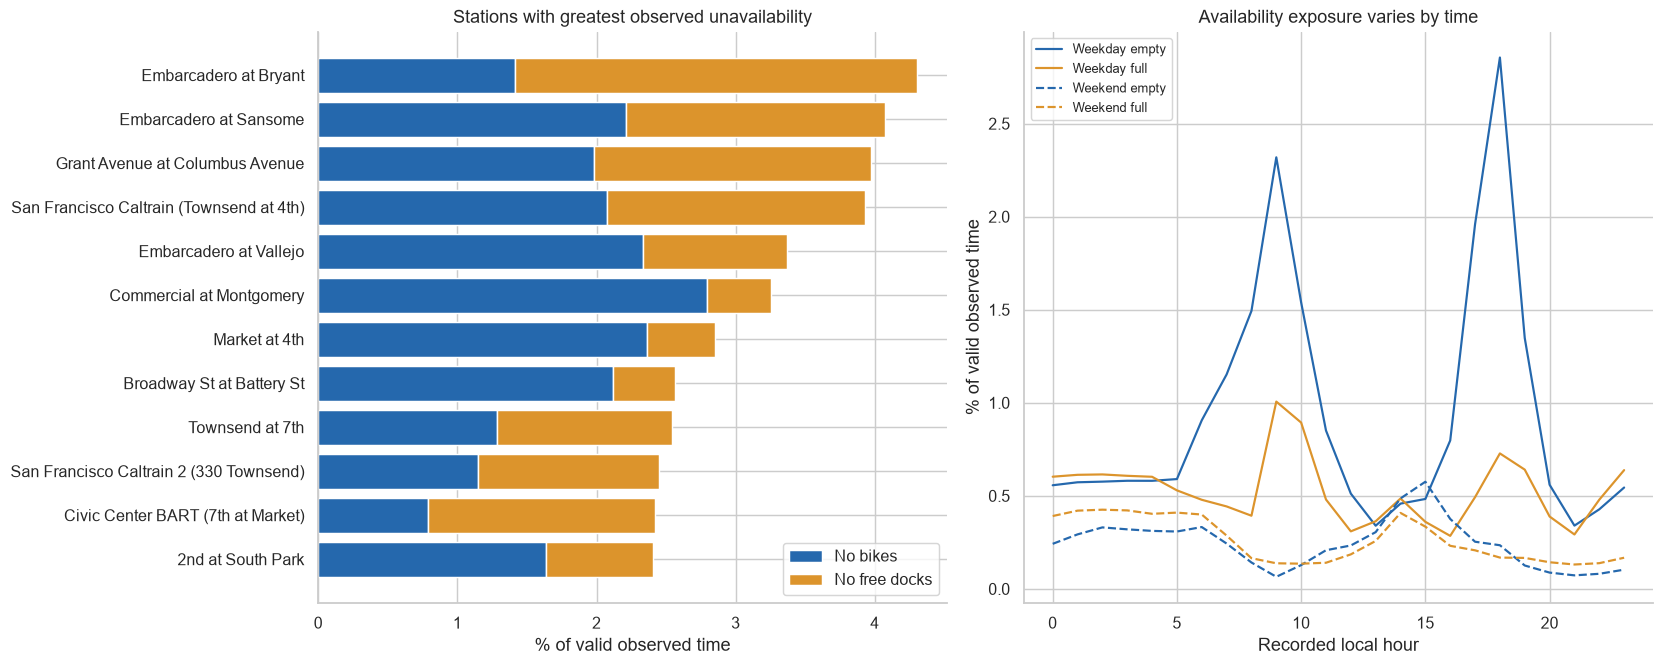

**Does the new dataset reveal availability constraints?** Yes: stations are empty for 0.74% and full for 0.45% of valid observed time. These are time shares, not percentages of customers or counts of lost trips.

In [10]:
availability=export(q("""SELECT a.station_id,s.station_name,s.city,
 sum(observed_seconds)/3600 observed_hours,sum(empty_seconds)/3600 empty_hours,sum(full_seconds)/3600 full_hours,
 100.0*sum(empty_seconds)/sum(observed_seconds) empty_pct,
 100.0*sum(full_seconds)/sum(observed_seconds) full_pct,
 100.0*sum(low_bike_seconds)/sum(observed_seconds) low_bike_pct,
 100.0*sum(low_dock_seconds)/sum(observed_seconds) low_dock_pct
 FROM status_hourly a JOIN station s USING(station_id) GROUP BY 1,2,3"""),'station_availability')
availability['unavailable_pct']=availability.empty_pct+availability.full_pct
overall=q('SELECT sum(observed_seconds) exposure_s,sum(empty_seconds) empty_s,sum(full_seconds) full_s FROM status_hourly').iloc[0]
metrics.update(observed_station_hours=float(overall.exposure_s/3600),empty_pct=float(100*overall.empty_s/overall.exposure_s),full_pct=float(100*overall.full_s/overall.exposure_s))
profile=export(q("""SELECT day_type,hour,sum(observed_seconds) observed_seconds,
 100.0*sum(empty_seconds)/sum(observed_seconds) empty_pct,
 100.0*sum(full_seconds)/sum(observed_seconds) full_pct
 FROM station_hour_panel GROUP BY 1,2 ORDER BY 1,2"""),'hourly_availability_profile')
fig,axes=plt.subplots(1,2,figsize=(16,6.5))
p=availability.nlargest(12,'unavailable_pct').sort_values('unavailable_pct')
axes[0].barh(p.station_name,p.empty_pct,color=BLUE,label='No bikes'); axes[0].barh(p.station_name,p.full_pct,left=p.empty_pct,color=ORANGE,label='No free docks')
axes[0].legend(); axes[0].set(xlabel='% of valid observed time',title='Stations with greatest observed unavailability')
for kind,style in [('Weekday','-'),('Weekend','--')]:
    p=profile[profile.day_type.eq(kind)]
    axes[1].plot(p.hour,p.empty_pct,color=BLUE,ls=style,label=kind+' empty')
    axes[1].plot(p.hour,p.full_pct,color=ORANGE,ls=style,label=kind+' full')
axes[1].legend(fontsize=9); axes[1].set(xlabel='Recorded local hour',ylabel='% of valid observed time',title='Availability exposure varies by time')
save(fig,'09_empty_full_exposure','Does the new dataset reveal availability constraints?',
     f'Yes: stations are empty for {metrics["empty_pct"]:.2f}% and full for {metrics["full_pct"]:.2f}% of valid observed time. These are time shares, not percentages of customers or counts of lost trips.')

## 10. Do high-volume stations also have high availability exposure?
This is a descriptive association. High demand may cause empty/full states, while those states may suppress completed trips.
Existing operator interventions also affect both quantities. A scatterplot cannot identify the direction of causation.

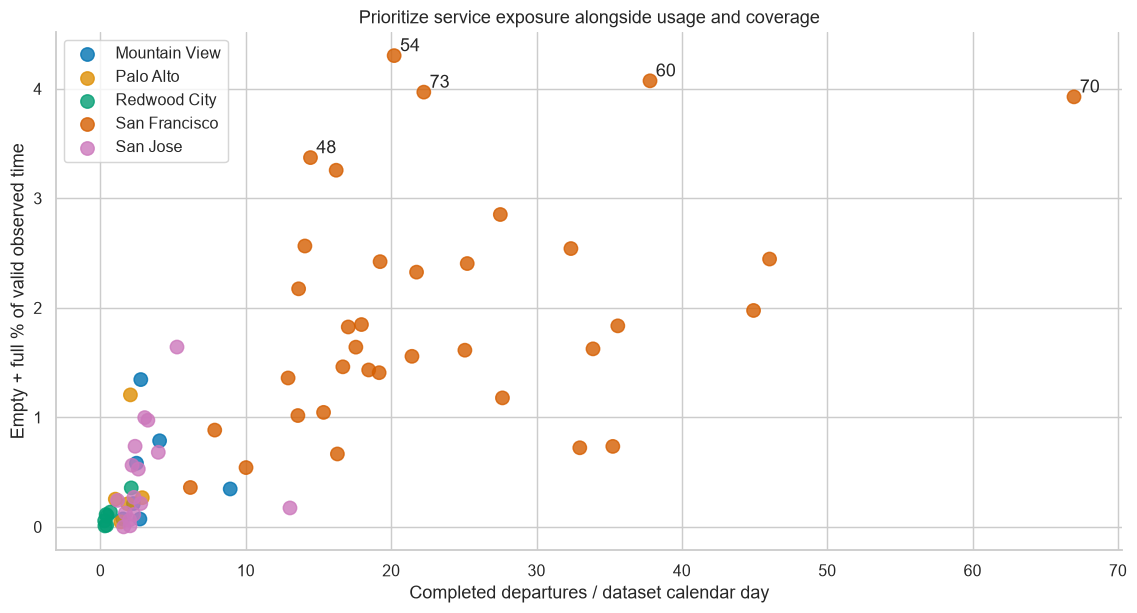

**Which stations warrant a pilot redistribution study?** Use activity, empty/full exposure and observation coverage jointly. Low observed usage is not evidence of low latent demand.

In [11]:
priority=availability.merge(station_flows[['departures','arrivals']].reset_index(),on='station_id',validate='one_to_one')
priority=priority.merge(coverage[['station_id','coverage']],on='station_id',validate='one_to_one')
priority['trips_per_reference_day']=priority.departures/len(dates)
export(priority.sort_values('unavailable_pct',ascending=False),'station_priority_evidence')
fig,ax=plt.subplots(figsize=(11,6))
for city,p in priority.groupby('city'):
    ax.scatter(p.trips_per_reference_day,p.unavailable_pct,s=25+60*p.coverage,label=city,alpha=.8)
for r in priority.nlargest(5,'unavailable_pct').itertuples(): ax.annotate(str(r.station_id),(r.trips_per_reference_day,r.unavailable_pct),xytext=(4,3),textcoords='offset points')
ax.legend(); ax.set(xlabel='Completed departures / dataset calendar day',ylabel='Empty + full % of valid observed time',title='Prioritize service exposure alongside usage and coverage')
save(fig,'10_usage_vs_availability','Which stations warrant a pilot redistribution study?',
     'Use activity, empty/full exposure and observation coverage jointly. Low observed usage is not evidence of low latent demand.')

## 11. Does the answer depend on status-coverage and gap rules?
Compare full-day station records with at least 50%, 75% or 90% valid exposure.
Also vary the permitted next-snapshot gap. Every rate retains its own observed-time denominator.

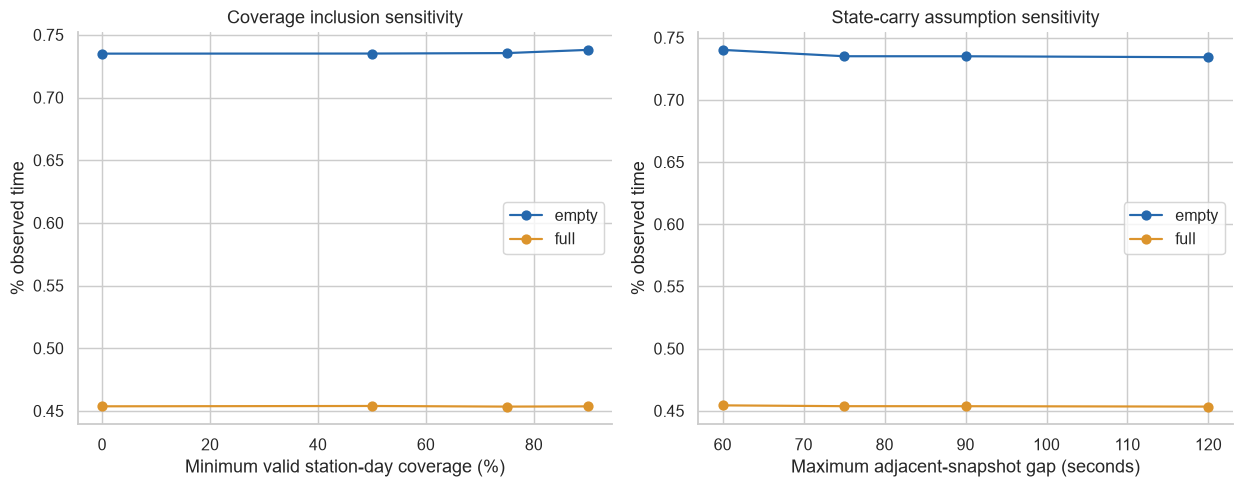

**Are exposure estimates robust to reasonable cleaning choices?** Compare the curves and accompanying denominator counts. A strict 60-second rule may reject ordinary clock jitter; long gaps are never filled in the primary analysis.

In [12]:
sd=q('SELECT * FROM station_daily ORDER BY date,station_id')
coverage_sensitivity=[]
for threshold in [0,.5,.75,.9]:
    p=sd[sd.observed_seconds.ge(threshold*86400)&sd.observed_seconds.gt(0)]
    coverage_sensitivity.append({'minimum_day_coverage':threshold,'station_days':len(p),'observed_hours':p.observed_seconds.sum()/3600,
        'empty_pct':100*p.empty_seconds.sum()/p.observed_seconds.sum(),'full_pct':100*p.full_seconds.sum()/p.observed_seconds.sum()})
cs=export(pd.DataFrame(coverage_sensitivity),'coverage_sensitivity')
gs=export(q("""WITH i AS (SELECT *,date_diff('second',observed_at,next_observed_at) gap_seconds FROM status_intervals WHERE valid_state),
 limits AS (SELECT unnest([60,75,90,120]) gap_limit_seconds)
 SELECT gap_limit_seconds,sum(gap_seconds)/3600.0 observed_hours,
 100.0*sum(CASE WHEN bikes_available=0 THEN gap_seconds ELSE 0 END)/sum(gap_seconds) empty_pct,
 100.0*sum(CASE WHEN docks_available=0 THEN gap_seconds ELSE 0 END)/sum(gap_seconds) full_pct
 FROM i CROSS JOIN limits WHERE gap_seconds>0 AND gap_seconds<=gap_limit_seconds GROUP BY 1 ORDER BY 1"""),'gap_tolerance_sensitivity')
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
for c,color in [('empty_pct',BLUE),('full_pct',ORANGE)]:
    axes[0].plot(cs.minimum_day_coverage*100,cs[c],marker='o',color=color,label=c.replace('_pct',''))
    axes[1].plot(gs.gap_limit_seconds,gs[c],marker='o',color=color,label=c.replace('_pct',''))
axes[0].set(xlabel='Minimum valid station-day coverage (%)',ylabel='% observed time',title='Coverage inclusion sensitivity'); axes[0].legend()
axes[1].set(xlabel='Maximum adjacent-snapshot gap (seconds)',ylabel='% observed time',title='State-carry assumption sensitivity'); axes[1].legend()
save(fig,'11_availability_sensitivity','Are exposure estimates robust to reasonable cleaning choices?',
     'Compare the curves and accompanying denominator counts. A strict 60-second rule may reject ordinary clock jitter; long gaps are never filled in the primary analysis.')

## 12. Inferential comparison: weekday versus weekend usage
Use a fixed cohort of SF stations installed by the first trip date. Exclude boundary days.
Pair each full calendar week's weekday mean with its weekend mean, then bootstrap contiguous four-week blocks.
This avoids treating individual trips or minute snapshots as independent observations.
Intervals summarize variability under repeated similar blocks of the historical process; they do not establish future or causal effects.

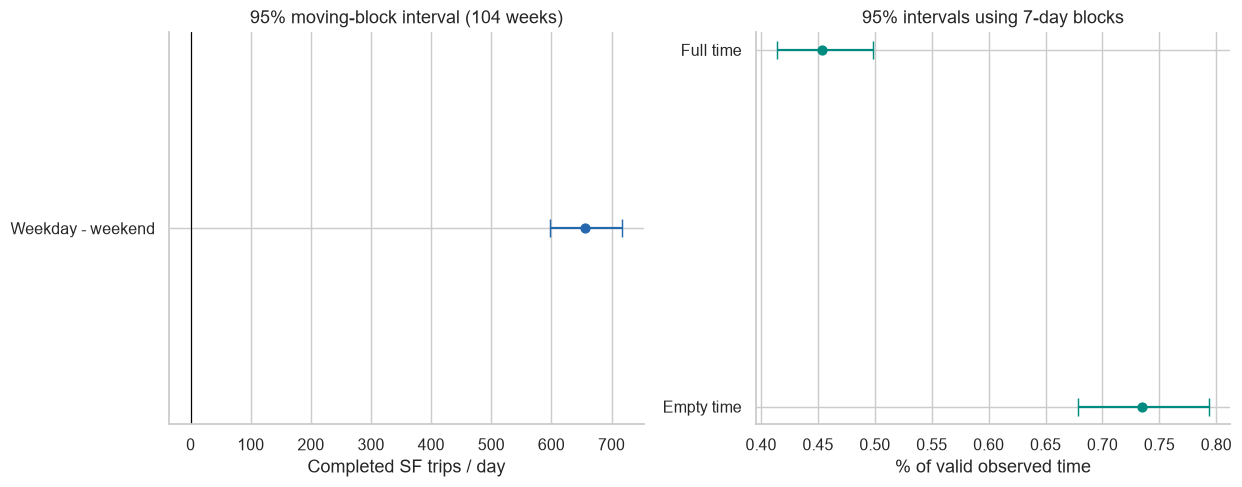

**Are the patterns larger than ordinary week-to-week variability?** For a fixed 34-station SF cohort, weekday usage exceeds weekend usage by 655.4 completed trips/day (95% four-week-block interval 597.8 to 717.9). This is an association in the observed period.

In [13]:
rng=np.random.default_rng(5103)
def moving_block_indices(n,block,rng):
    starts=rng.integers(0,n-block+1,size=math.ceil(n/block))
    return np.concatenate([np.arange(s,s+block) for s in starts])[:n]
def block_mean_ci(values,block=4,reps=2000):
    x=np.asarray(values,dtype=float); block=min(block,len(x))
    estimates=np.array([x[moving_block_indices(len(x),block,rng)].mean() for _ in range(reps)])
    return float(x.mean()),*[float(x) for x in np.quantile(estimates,[.025,.975])]
cohort=station[(station.city=='San Francisco')&station.installation_date.le(start.normalize())].index
sf_daily=(trips[trips.start_station_id.isin(cohort)].groupby('date').size().reindex(dates,fill_value=0).rename('departures').to_frame())
sf_daily=sf_daily.iloc[1:-1].copy(); sf_daily.index.name='date'
sf_daily['weekday']=sf_daily.index.day_of_week<5
sf_daily['week']=sf_daily.index-pd.to_timedelta(sf_daily.index.day_of_week,unit='D')
weekly=sf_daily.groupby('week').agg(days=('departures','size'))
paired=sf_daily.groupby(['week','weekday']).departures.agg(['mean','size']).unstack('weekday')
paired=paired[(paired[('size',True)]==5)&(paired[('size',False)]==2)]
effects=paired[('mean',True)]-paired[('mean',False)]
effect,lo,hi=block_mean_ci(effects)
metrics['weekday_inference']={'cohort_stations':len(cohort),'complete_weeks':len(effects),'mean_difference':effect,'ci_low':lo,'ci_high':hi,'block_weeks':4}
export(pd.DataFrame({'week':effects.index,'weekday_mean':paired[('mean',True)].values,'weekend_mean':paired[('mean',False)].values,'difference':effects.values}),'weekly_paired_comparison')
daily_av=sd.groupby('date')[['observed_seconds','empty_seconds','full_seconds']].sum(min_count=1).reindex(dates).fillna(0)
availability_inference=[]
for column,label in [('empty_seconds','Empty time'),('full_seconds','Full time')]:
    a=daily_av[[column,'observed_seconds']].to_numpy(float)
    boots=[]
    for _ in range(2000):
        p=a[moving_block_indices(len(a),7,rng)]
        boots.append(100*p[:,0].sum()/p[:,1].sum())
    lower,upper=np.quantile(boots,[.025,.975])
    availability_inference.append({'measure':label,'pct':100*a[:,0].sum()/a[:,1].sum(),'ci_low':lower,'ci_high':upper,'block_days':7})
ai=export(pd.DataFrame(availability_inference),'availability_block_intervals')
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
axes[0].errorbar([effect],[0],xerr=[[effect-lo],[hi-effect]],fmt='o',color=BLUE,capsize=6)
axes[0].axvline(0,color='black',lw=.8); axes[0].set_yticks([0],['Weekday - weekend']); axes[0].set(xlabel='Completed SF trips / day',title=f'95% moving-block interval ({len(effects)} weeks)')
axes[1].errorbar(ai.pct,np.arange(2),xerr=[ai.pct-ai.ci_low,ai.ci_high-ai.pct],fmt='o',color=TEAL,capsize=6)
axes[1].set_yticks(range(2),ai.measure); axes[1].set(xlabel='% of valid observed time',title='95% intervals using 7-day blocks')
save(fig,'12_block_inference','Are the patterns larger than ordinary week-to-week variability?',
     f'For a fixed {len(cohort)}-station SF cohort, weekday usage exceeds weekend usage by {effect:.1f} completed trips/day (95% four-week-block interval {lo:.1f} to {hi:.1f}). This is an association in the observed period.')

## 13. Inferential weather association with controls
SF-only fixed station cohort; one daily weather proxy (94107). Model log(1 + daily completed trips).
Controls: weekday, calendar month, year, linear time trend, mean temperature and wind.
OLS uncertainty uses a Newey-West/Bartlett HAC covariance (28 lags); 1.96 asymptotic intervals.
Repeat with trace precipitation treated as rain. This is exploratory association, not a causal demand elasticity.

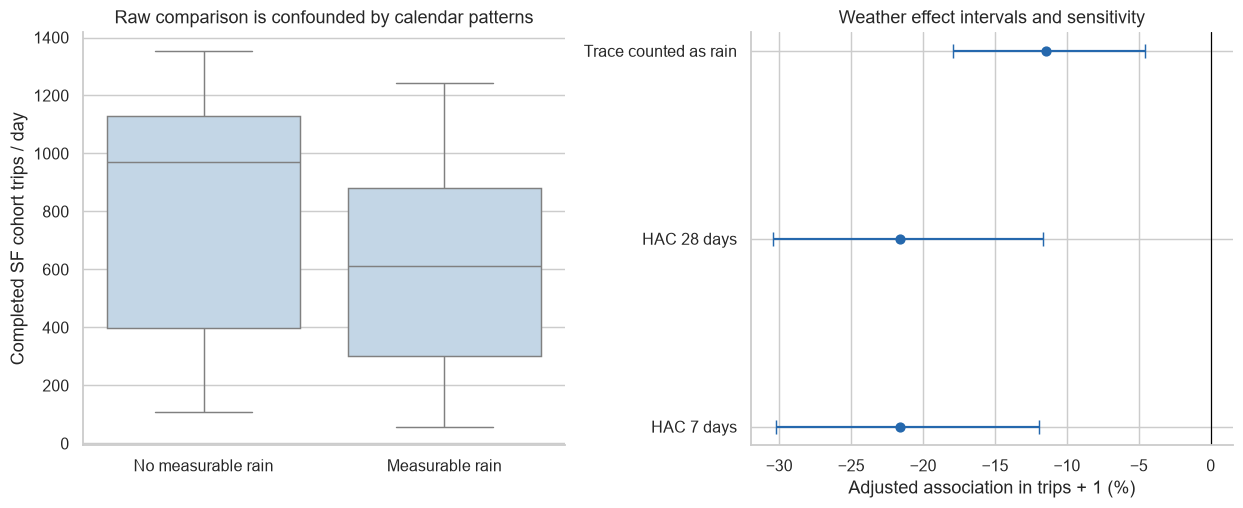

**Is rain associated with lower usage after calendar controls?** The adjusted rain association is -21.6% in trips+1 (95% HAC interval -30.4% to -11.7%). Unmeasured confounders and availability censoring prevent a causal interpretation.

In [14]:
sf_weather=weather[weather.weather_zip_code.eq('94107')].set_index('weather_date')
reg=sf_daily.join(sf_weather[['precipitation_numeric_inches','trace_precipitation','temperature_f','wind_mph']],how='left',validate='one_to_one')
reg=reg.dropna(subset=['temperature_f','wind_mph','precipitation_numeric_inches'])
def hac_regression(trace_is_rain=False,lag=28):
    rain=reg.precipitation_numeric_inches.gt(0)
    if trace_is_rain: rain=rain|reg.trace_precipitation.fillna(False)
    X=pd.DataFrame({'intercept':1.0,'rain':rain.astype(float),'temperature_10f':reg.temperature_f/10,'wind_10mph':reg.wind_mph/10,
                    'time_trend':np.arange(len(reg))/len(reg)},index=reg.index)
    for label,vals in [('weekday',reg.index.day_of_week),('month',reg.index.month),('year',reg.index.year)]:
        dummy=pd.get_dummies(pd.Series(vals,index=reg.index),prefix=label,drop_first=True,dtype=float)
        X=pd.concat([X,dummy],axis=1)
    x=X.to_numpy(float); y=np.log1p(reg.departures.to_numpy(float))
    assert np.linalg.matrix_rank(x)==x.shape[1]
    beta=np.linalg.lstsq(x,y,rcond=None)[0]; resid=y-x@beta
    assert np.max(np.abs(x.T@resid))<1e-6
    z=x*resid[:,None]; meat=z.T@z
    for k in range(1,min(lag,len(y)-1)+1):
        gamma=z[k:].T@z[:-k]; meat+=(1-k/(lag+1))*(gamma+gamma.T)
    bread=np.linalg.inv(x.T@x); covariance=bread@meat@bread*len(y)/(len(y)-x.shape[1])
    se=np.sqrt(np.maximum(np.diag(covariance),0)); j=list(X).index('rain')
    return {'trace_treated_as_rain':trace_is_rain,'lag_days':lag,'days':len(y),'rain_days':int(rain.sum()),
        'rain_log_coefficient':beta[j],'hac_standard_error':se[j],
        'rain_association_pct':100*np.expm1(beta[j]),
        'ci_low_pct':100*np.expm1(beta[j]-1.96*se[j]),'ci_high_pct':100*np.expm1(beta[j]+1.96*se[j]),
        'r_squared':1-(resid@resid)/np.sum((y-y.mean())**2)}
rr=export(pd.DataFrame([hac_regression(False,7),hac_regression(False,28),hac_regression(True,28)]),'weather_regression')
metrics['weather_regression']=rr.iloc[1].to_dict()
fig,axes=plt.subplots(1,2,figsize=(12,5))
plot=reg.assign(rain=np.where(reg.precipitation_numeric_inches.gt(0),'Measurable rain','No measurable rain'))
sns.boxplot(data=plot,x='rain',y='departures',ax=axes[0],color='#bdd7ec',showfliers=False)
axes[0].set(xlabel='',ylabel='Completed SF cohort trips / day',title='Raw comparison is confounded by calendar patterns')
axes[1].errorbar(rr.rain_association_pct,range(len(rr)),xerr=[rr.rain_association_pct-rr.ci_low_pct,rr.ci_high_pct-rr.rain_association_pct],fmt='o',color=BLUE,capsize=5)
axes[1].set_yticks(range(len(rr)),['HAC 7 days','HAC 28 days','Trace counted as rain']); axes[1].axvline(0,color='black',lw=.8)
axes[1].set(xlabel='Adjusted association in trips + 1 (%)',title='Weather effect intervals and sensitivity')
r=rr.iloc[1]
save(fig,'13_weather_association','Is rain associated with lower usage after calendar controls?',
     f'The adjusted rain association is {r.rain_association_pct:+.1f}% in trips+1 (95% HAC interval {r.ci_low_pct:+.1f}% to {r.ci_high_pct:+.1f}%). Unmeasured confounders and availability censoring prevent a causal interpretation.')

## 14. Can a simple historical profile forecast completed station trips?
Last 60 calendar days are held out. Train only on earlier station-hours, including zero-trip hours.
Fallback for a new station/group is explicitly the training station-hour mean, then the global mean.
This validates completed-trip forecasts, not unseen demand during stockouts or economic returns.

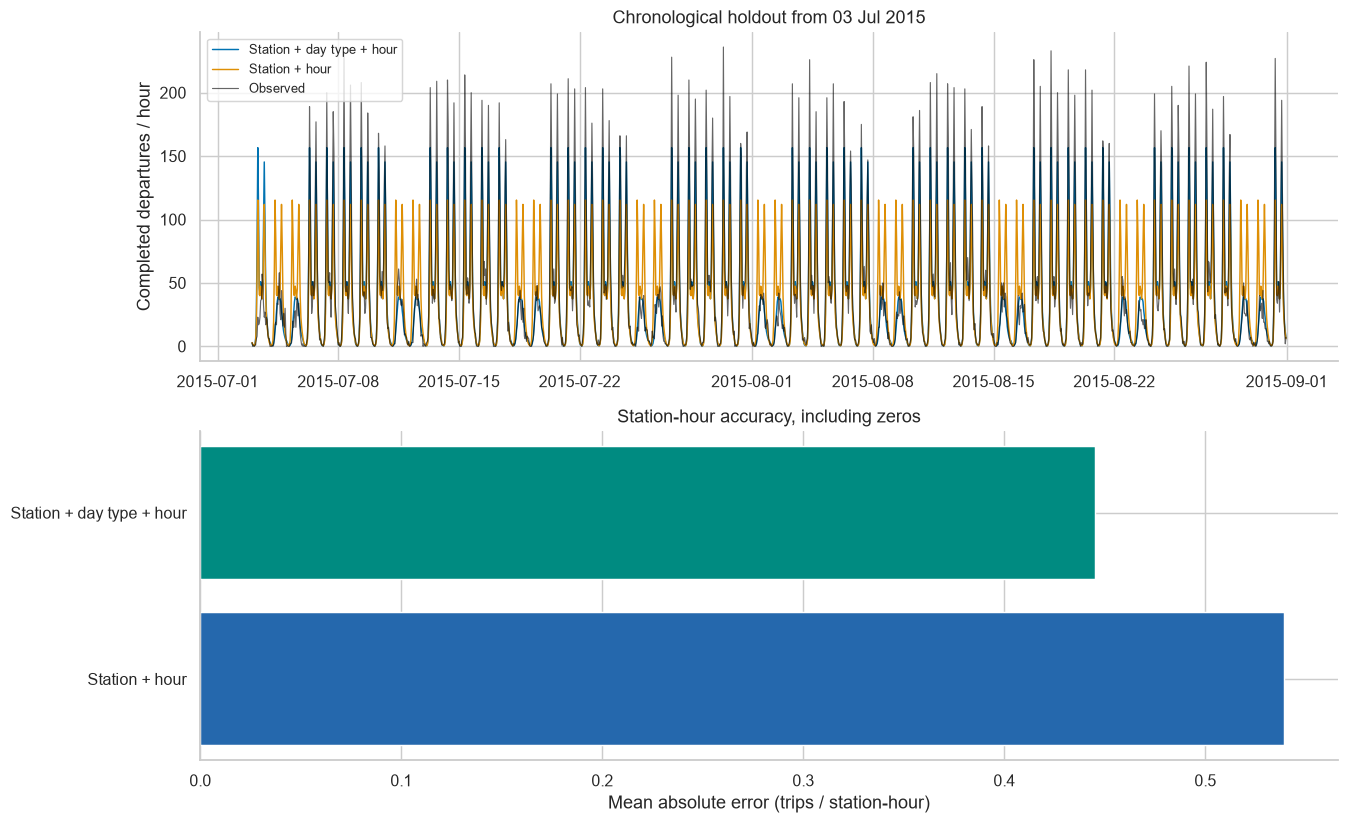

**Does a transparent baseline support scenario construction?** The two held-out MAEs are 0.539 and 0.445. Peak-hour errors and bias are reported separately; forecast accuracy alone does not validate a redistribution policy.

In [15]:
panel=q('SELECT station_id,hour_start,day_type,hour,departures,arrivals FROM station_hour_panel ORDER BY hour_start,station_id')
cutoff=end.normalize()-pd.Timedelta(days=59)
train=panel[panel.hour_start.lt(cutoff)].copy(); test=panel[panel.hour_start.ge(cutoff)].copy()
results=[]; forecast_rows=[]
for label,cols in [('Station + hour',['station_id','hour']),('Station + day type + hour',['station_id','day_type','hour'])]:
    means=train.groupby(cols).departures.mean().rename('prediction').reset_index()
    p=test.merge(means,on=cols,how='left',validate='many_to_one')
    fallback=train.groupby(['station_id','hour']).departures.mean()
    missing=int(p.prediction.isna().sum())
    if missing:
        f=pd.MultiIndex.from_frame(p[['station_id','hour']]).map(fallback)
        p['prediction']=p.prediction.fillna(pd.Series(f,index=p.index)).fillna(train.departures.mean())
    error=p.prediction-p.departures
    peak=p.day_type.eq('Weekday')&p.hour.isin([7,8,9,16,17,18])
    results.append({'method':label,'MAE':error.abs().mean(),'RMSE':np.sqrt(np.mean(error**2)),
                    'bias':error.mean(),'peak_MAE':error[peak].abs().mean(),'test_station_hours':len(p),'fallback_rows':missing})
    p['method']=label; forecast_rows.append(p)
fm=export(pd.DataFrame(results),'forecast_metrics')
predictions=pd.concat(forecast_rows,ignore_index=True)
export(predictions.groupby(['hour_start','method'])[['departures','prediction']].sum().reset_index(),'forecast_system_hourly')
metrics['forecast_cutoff']=str(cutoff); metrics['forecast_metrics']=fm.to_dict('records')
fig,axes=plt.subplots(2,1,figsize=(13,8))
aggregate=predictions.groupby(['hour_start','method'])[['departures','prediction']].sum().reset_index()
for label,p in aggregate.groupby('method'): axes[0].plot(p.hour_start,p.prediction,lw=1,label=label)
p=aggregate[aggregate.method.eq(results[0]['method'])]; axes[0].plot(p.hour_start,p.departures,color='black',lw=.8,alpha=.6,label='Observed')
axes[0].legend(fontsize=9); axes[0].set(ylabel='Completed departures / hour',title=f'Chronological holdout from {cutoff:%d %b %Y}')
axes[1].barh(fm.method,fm.MAE,color=[BLUE,TEAL]); axes[1].set(xlabel='Mean absolute error (trips / station-hour)',title='Station-hour accuracy, including zeros')
save(fig,'14_forecast_baselines','Does a transparent baseline support scenario construction?',
     f'The two held-out MAEs are {fm.MAE.iloc[0]:.3f} and {fm.MAE.iloc[1]:.3f}. Peak-hour errors and bias are reported separately; forecast accuracy alone does not validate a redistribution policy.')

## 15. What data gaps remain for a business case?
Inventory observations and static dock counts improve feasibility modeling, but do not supply work orders,
failed customer requests, payments, historical tariffs, acquisition prices or marginal relocation costs.
Financial assumptions must match this system and 2013-2015; current Citi Bike prices cannot stand in for observed SF revenue.

In [16]:
gap_rows=[
 ('Station capacity','Partly closed','Static dock_count exists, but availability totals may differ. Historical capacity/outage series remains absent.'),
 ('Historical inventory','Partly closed','Available-bike and free-dock snapshots exist; coverage gaps, disabled equipment and operator interventions remain.'),
 ('Unfulfilled orders','Still missing','Zero bikes/docks reveal availability exposure, not how many customers arrived and left. Latent demand must be estimated.'),
 ('Bike identity','Improved','bike_id links trips, but contains no purchase dates, maintenance history, retirement or customer identity.'),
 ('Maintenance and parts','Still missing','No inspection schedule, work order, repair cost, downtime reason or spare-part inventory.'),
 ('Rebalancing operations','Still missing','No staff move log, truck/depot, loading time, fuel, wage or capacity record.'),
 ('Capital expenditure','Still missing','No bike/dock procurement prices, useful lives, financing or replacement schedule.'),
 ('Revenue and profit','Still missing','No charged fare, subscription account, payment, refunds, tax, sponsorship, subsidy or local profit statement.'),
 ('Weather','Improved','Daily proxy observations exist; city mapping and trace-rain treatment are explicit assumptions.'),
 ('Travel costs','Still missing','Coordinates support distance lower bounds, not road times, truck costs or feasible routes.'),
 ('Security and technology','Still missing','No theft/loss value, insurance/security, connectivity, platform or data costs.'),
]
gap_table=export(pd.DataFrame(gap_rows,columns=['input','assessment','evidence_or_gap']),'business_case_gap_assessment'); show(gap_table)
assumptions=pd.DataFrame([
 ('relocation_cost_per_bike','USD/bike'),('truck_activation_cost','USD/shift'),('truck_capacity','bikes'),
 ('loading_time','minutes/bike'),('bike_purchase_cost','USD/bike'),('dock_purchase_cost','USD/dock'),
 ('annual_maintenance_cost','USD/bike/year'),('lost_rental_penalty','USD/request'),('marginal_paid_trip_contribution','USD/trip'),
 ('starting_bikes','bikes/station'),('historical_capacity_override','docks/station')],columns=['parameter','unit'])
assumptions['value']=np.nan; assumptions['evidence_source']='Required: evidence or explicitly labeled scenario assumption'
export(assumptions,'financial_and_operating_inputs_template')
checks={
 'trip_rows_preserved':metrics['raw_trip_rows']==len(trips),
 'all_trip_station_keys_resolved':len(trips)==int(keys.loc[keys.table_name.eq('trip'),'rows'].iloc[0]),
 'no_train_test_timestamp_overlap':not set(train.hour_start).intersection(set(test.hour_start)),
 'nonnegative_availability_rates':bool(availability[['empty_pct','full_pct']].ge(0).all().all()),
 'empty_full_disjoint':bool(availability.unavailable_pct.le(100+1e-8).all()),
 'coverage_never_exceeds_reference':bool(coverage.coverage.le(1+1e-8).all()),
 'weather_rows_do_not_multiply_daily_records':len(reg)<=len(sf_daily),
 'dense_departures_reconcile':int(panel.departures.sum())==len(trips),
 'dense_arrivals_reconcile':int(panel.arrivals.sum())==len(trips),
 'all_figure_topics_saved':len(figure_notes)==14,
}
assert all(checks.values()),checks
metrics['validation']=checks
metrics['source_keys']=keys.to_dict('records')
metrics['availability_intervals']=ai.to_dict('records')
metrics['top_unavailability_stations']=priority.nlargest(5,'unavailable_pct')[['station_id','station_name','city','unavailable_pct','coverage']].to_dict('records')
metrics['trace_weather_rows']=int(weather.trace_precipitation.fillna(False).sum())
metrics['pandas']=pd.__version__; metrics['numpy']=np.__version__; metrics['duckdb']=duckdb.__version__
(OUT/'analysis_manifest.json').write_text(json.dumps(metrics,indent=2,default=str),encoding='utf-8')
schema=q("SELECT sql FROM duckdb_tables() WHERE NOT internal ORDER BY table_name").sql.dropna().tolist()
indexes=q("SELECT sql FROM duckdb_indexes() ORDER BY index_name").sql.dropna().tolist()
(OUT/'database_schema_actual.sql').write_text('-- Actual materialized-table DDL and indexes. Views and audited logical FKs are documented in the source builder.\n\n'+'\n\n'.join(schema+indexes),encoding='utf-8')
export(pd.DataFrame(figure_notes),'figure_questions_and_findings')
from write_report import write_report
write_report(metrics,figure_notes,OUT)
say('**Complete.** Relational database, 14 chart panels, auditable tables, inferential estimates and a gap report are saved. No optimization solution, actual lost-order count or realized profit is claimed.')
con.close()

,input,assessment,evidence_or_gap
0,Station capacity,Partly closed,"Static dock_count exists, but availability tot..."
1,Historical inventory,Partly closed,Available-bike and free-dock snapshots exist; ...
2,Unfulfilled orders,Still missing,"Zero bikes/docks reveal availability exposure,..."
3,Bike identity,Improved,"bike_id links trips, but contains no purchase ..."
4,Maintenance and parts,Still missing,"No inspection schedule, work order, repair cos..."
5,Rebalancing operations,Still missing,"No staff move log, truck/depot, loading time, ..."
6,Capital expenditure,Still missing,"No bike/dock procurement prices, useful lives,..."
7,Revenue and profit,Still missing,"No charged fare, subscription account, payment..."
8,Weather,Improved,Daily proxy observations exist; city mapping a...
9,Travel costs,Still missing,"Coordinates support distance lower bounds, not..."


Report saved: C:\Users\Carlo\Desktop\SEM 3 MSBA\Operations research\output\sf_bikeshare\SF_Bikeshare_Inferential_Report.pdf


**Complete.** Relational database, 14 chart panels, auditable tables, inferential estimates and a gap report are saved. No optimization solution, actual lost-order count or realized profit is claimed.